# Fine-Tune + LR and 5-Fold CV Comparison
Requires `finetune_setup.ipynb` and `finetune_blocks.ipynb` to have been run first.

Experiments:
1. Fine-tuned BrainOmni + LR (80/10/10 split)
2. Fine-tuned BrainOmni + LR (5-fold CV) — fair comparison against frozen baseline

In [1]:
import os, sys, json
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt
from tqdm import tqdm

sys.path.insert(0, '/Users/faenegoro/Documents/Neuroimaging/BrainOmni')
from brainomni.model import BrainOmni

device = torch.device('mps') if torch.backends.mps.is_available() else torch.device('cpu')
print('Device:', device)

W0708 02:19:39.120000 20636 site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Device: mps


In [2]:
CKPT_PATH = '/Users/faenegoro/Documents/Neuroimaging/BrainOmni/ckpt_collection/tiny'
SAVE_DIR  = '../data/preprocessed'
OUT_DIR   = '../results/figures'
os.makedirs(OUT_DIR, exist_ok=True)

with open(os.path.join(CKPT_PATH, 'model_cfg.json')) as f:
    model_config = json.load(f)
base_checkpoint = torch.load(
    os.path.join(CKPT_PATH, 'BrainOmni.pt'), map_location='cpu', weights_only=True
)

proj_out1 = np.load(os.path.join(SAVE_DIR, 'proj_out1.npy'))  # (N, 16, NT, 256)
proj_out2 = np.load(os.path.join(SAVE_DIR, 'proj_out2.npy'))
labels    = np.load(os.path.join(SAVE_DIR, 'labels.npy'))
split     = np.load(os.path.join(SAVE_DIR, 'split.npz'))
train_idx, val_idx, test_idx = split['train_idx'], split['val_idx'], split['test_idx']

ft_results = torch.load(os.path.join(SAVE_DIR, 'ft_results.pt'), weights_only=False)
print(f'Loaded {len(proj_out1)} subjects | proj_out shape: {proj_out1.shape}')
print(f'ft_results keys: {list(ft_results.keys())}')

Loaded 148 subjects | proj_out shape: (148, 16, 160, 256)
ft_results keys: [10, 9, 8]


In [3]:
class CachedMEGDataset(Dataset):
    def __init__(self, indices, cached1, cached2, labels):
        self.indices = indices
        self.cached1 = cached1
        self.cached2 = cached2
        self.labels  = labels
    def __len__(self): return len(self.indices)
    def __getitem__(self, i):
        idx = self.indices[i]
        return self.cached1[idx], self.cached2[idx], torch.tensor(self.labels[idx], dtype=torch.long)

class FinetuneClassifier(nn.Module):
    def __init__(self, encoder_blocks, hidden_dim=256):
        super().__init__()
        self.blocks = encoder_blocks
        self.head = nn.Sequential(
            nn.Linear(hidden_dim * 16, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, 2)
        )
    def forward(self, x1, x2):
        x1, x2 = x1.to(device), x2.to(device)
        for block in self.blocks:
            x1 = block(x1)
            x2 = block(x2)
        x1 = F.normalize(x1, p=2.0, dim=-1, eps=1e-6).mean(dim=2)
        x2 = F.normalize(x2, p=2.0, dim=-1, eps=1e-6).mean(dim=2)
        return self.head(((x1 + x2) / 2).flatten(1))

def extract_features(model_ft, ft_classifier_blocks, n_frozen_val):
    """Run all subjects through frozen + fine-tuned blocks, return (N, 4096) features."""
    features = []
    with torch.no_grad():
        for i in range(len(proj_out1)):
            x1 = torch.tensor(proj_out1[i]).unsqueeze(0).to(device)
            x2 = torch.tensor(proj_out2[i]).unsqueeze(0).to(device)
            for block in list(model_ft.blocks)[:n_frozen_val]:
                x1 = block(x1)
                x2 = block(x2)
            for block in ft_classifier_blocks:
                x1 = block(x1)
                x2 = block(x2)
            x1 = F.normalize(x1, p=2.0, dim=-1, eps=1e-6).mean(dim=2).flatten(1)
            x2 = F.normalize(x2, p=2.0, dim=-1, eps=1e-6).mean(dim=2).flatten(1)
            feat = ((x1 + x2) / 2).squeeze(0).cpu().numpy()
            features.append(feat)
    return np.array(features)

print('Helpers ready.')

Helpers ready.


## Experiment 1: Fine-tuned BrainOmni + LR (80/10/10 split)

In [4]:
print('=== Fine-tuned BrainOmni + LR (80/10/10 split) ===')
print(f'{"Unfrozen blocks":<20} {"Test Acc (LR)"}')
print('-' * 35)

ft_lr_results = {}
for n_frozen, res in ft_results.items():
    model_ft = BrainOmni(**model_config)
    model_ft.load_state_dict(base_checkpoint, strict=False)
    for param in model_ft.parameters():
        param.requires_grad = False
    model_ft = model_ft.to(device).eval()

    n_frozen_val = res['n_frozen']
    unfrozen_ft  = nn.ModuleList(list(model_ft.blocks)[n_frozen_val:-1])
    ft_classifier = FinetuneClassifier(unfrozen_ft, hidden_dim=256).to(device)
    ft_classifier.load_state_dict(res['best_weights'])
    ft_classifier.eval()

    features_all = extract_features(model_ft, ft_classifier.blocks, n_frozen_val)

    lr = LogisticRegression(max_iter=1000)
    lr.fit(features_all[train_idx], labels[train_idx])
    test_acc = accuracy_score(labels[test_idx], lr.predict(features_all[test_idx]))

    label = f'Last {res["n_unfrozen"]} block(s)'
    ft_lr_results[n_frozen] = {'n_unfrozen': res['n_unfrozen'], 'test_acc': test_acc}
    print(f'{label:<20} {test_acc:.3f}')

=== Fine-tuned BrainOmni + LR (80/10/10 split) ===
Unfrozen blocks      Test Acc (LR)
-----------------------------------


/opt/miniconda3/envs/brainomni/lib/python3.11/site-packages/torch/nn/utils/weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)


Last 1 block(s)      0.800


/opt/miniconda3/envs/brainomni/lib/python3.11/site-packages/torch/nn/utils/weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)


Last 2 block(s)      0.800


/opt/miniconda3/envs/brainomni/lib/python3.11/site-packages/torch/nn/utils/weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)


Last 3 block(s)      0.800


## Experiment 2: Fine-tuned BrainOmni + LR (5-fold CV)
Fair comparison against the frozen BrainOmni + LR baseline (83.1%) from evaluation.ipynb.

In [ ]:
import math
print('=== Fine-tuned BrainOmni + LR (5-fold CV, official recipe) ===')
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=123)
ft_cv_results = {}
ft_cv_folds   = {}

def make_warmup_cosine(optimizer, total_steps, warmup_ratio=0.1, warmup_min=0.1, cos_min=0.1):
    warmup_steps = max(1, int(total_steps * warmup_ratio))
    def lr_lambda(step):
        if step < warmup_steps:
            return warmup_min + (1 - warmup_min) * step / warmup_steps
        prog = (step - warmup_steps) / max(1, total_steps - warmup_steps)
        return cos_min + (1 - cos_min) * 0.5 * (1 + math.cos(math.pi * prog))
    return torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda)

CV_EPOCHS = 40
for n_frozen_key in [10, 9, 8]:
    n_unfrozen = 11 - n_frozen_key
    fold_accs  = []

    for fold, (tr_idx, te_idx) in enumerate(skf.split(np.arange(len(labels)), labels)):
        model_cv = BrainOmni(**model_config)
        model_cv.load_state_dict(base_checkpoint, strict=False)
        for param in model_cv.parameters():
            param.requires_grad = False
        model_cv = model_cv.to(device).eval()

        # Cache frozen blocks — proj_out1/proj_out2 already tokenized
        cached1_cv, cached2_cv = [], []
        with torch.no_grad():
            for i in range(len(proj_out1)):
                x1 = torch.tensor(proj_out1[i]).unsqueeze(0).to(device)
                x2 = torch.tensor(proj_out2[i]).unsqueeze(0).to(device)
                for block in list(model_cv.blocks)[:n_frozen_key]:
                    x1 = block(x1)
                    x2 = block(x2)
                cached1_cv.append(x1.squeeze(0).cpu())
                cached2_cv.append(x2.squeeze(0).cpu())

        # Fine-tune on this fold — official recipe (AdamW, differential LR, warmup-cosine, label smoothing)
        train_loader_cv = DataLoader(
            CachedMEGDataset(tr_idx, cached1_cv, cached2_cv, labels), batch_size=8, shuffle=True
        )
        unfrozen_cv = nn.ModuleList(list(model_cv.blocks)[n_frozen_key:-1])
        for param in unfrozen_cv.parameters():
            param.requires_grad = True
        ft_cv = FinetuneClassifier(unfrozen_cv, hidden_dim=256).to(device)
        opt_cv = torch.optim.AdamW([
            {'params': ft_cv.blocks.parameters(), 'lr': 1e-5, 'weight_decay': 0.05},
            {'params': ft_cv.head.parameters(),   'lr': 1e-4, 'weight_decay': 0.05},
        ], betas=(0.9, 0.99), eps=1e-6)
        sched_cv = make_warmup_cosine(opt_cv, CV_EPOCHS * len(train_loader_cv))
        crit_cv  = nn.CrossEntropyLoss(label_smoothing=0.1)

        for epoch in range(CV_EPOCHS):
            ft_cv.train()
            for x1, x2, y in train_loader_cv:
                opt_cv.zero_grad()
                loss = crit_cv(ft_cv(x1, x2), y.to(device))
                loss.backward()
                torch.nn.utils.clip_grad_norm_(ft_cv.parameters(), max_norm=1.0)
                opt_cv.step()
                sched_cv.step()

        # Extract features and run LR
        ft_cv.eval()
        features_cv = extract_features(model_cv, ft_cv.blocks, n_frozen_key)
        lr_cv = LogisticRegression(max_iter=1000)
        lr_cv.fit(features_cv[tr_idx], labels[tr_idx])
        acc = accuracy_score(labels[te_idx], lr_cv.predict(features_cv[te_idx]))
        fold_accs.append(acc)
        print(f'  Last {n_unfrozen} block(s) | Fold {fold+1}: {acc:.3f}')

    mean_acc = np.mean(fold_accs)
    ft_cv_results[n_frozen_key] = mean_acc
    ft_cv_folds[n_frozen_key]   = fold_accs
    print(f'  Last {n_unfrozen} block(s) | Mean 5-fold CV: {mean_acc:.3f} '
          f'(std {np.std(fold_accs):.3f}, folds {[round(a,3) for a in fold_accs]})\n')

print('--- Baselines from evaluation.ipynb (5-fold CV) ---')
print('Frozen BrainOmni-tiny + LR:  0.831')
print('Handcrafted features + LR:   0.872')

=== Fine-tuned BrainOmni + LR (5-fold CV, official recipe) ===


/opt/miniconda3/envs/brainomni/lib/python3.11/site-packages/torch/nn/utils/weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)


  Last 1 block(s) | Fold 1: 0.667


/opt/miniconda3/envs/brainomni/lib/python3.11/site-packages/torch/nn/utils/weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)


  Last 1 block(s) | Fold 2: 0.967


/opt/miniconda3/envs/brainomni/lib/python3.11/site-packages/torch/nn/utils/weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)


  Last 1 block(s) | Fold 3: 0.900


/opt/miniconda3/envs/brainomni/lib/python3.11/site-packages/torch/nn/utils/weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)


## Comparison Plot

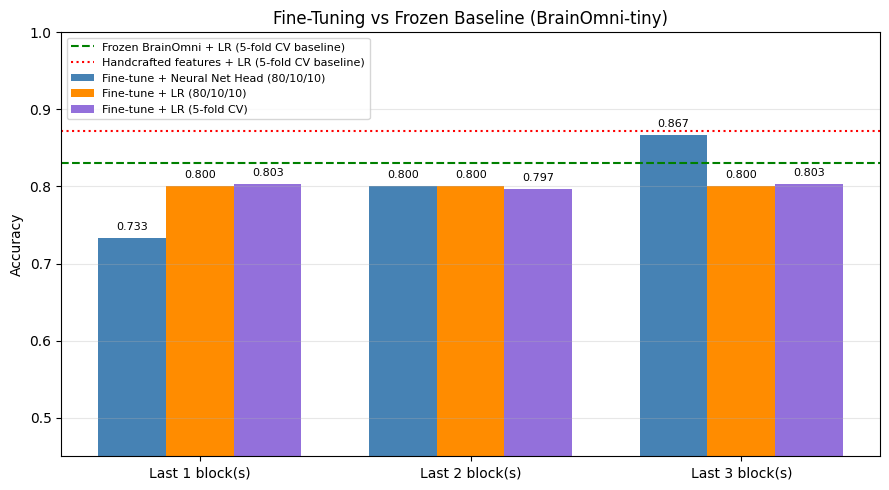

Saved finetune_full_comparison.png


In [ ]:
labels_x  = [f'Last {ft_results[nf]["n_unfrozen"]} block(s)' for nf in [10, 9, 8]]
head_accs = [ft_results[nf]['test_acc'] for nf in [10, 9, 8]]
lr_accs   = [ft_lr_results[nf]['test_acc'] for nf in [10, 9, 8]]
cv_accs   = [ft_cv_results[nf] for nf in [10, 9, 8]]

x     = np.arange(len(labels_x))
width = 0.25

fig, ax = plt.subplots(figsize=(9, 5))
bars1 = ax.bar(x - width, head_accs, width, label='Fine-tune + Neural Net Head (80/10/10)', color='steelblue')
bars2 = ax.bar(x,         lr_accs,   width, label='Fine-tune + LR (80/10/10)',              color='darkorange')
bars3 = ax.bar(x + width, cv_accs,   width, label='Fine-tune + LR (5-fold CV)',              color='mediumpurple')

ax.axhline(0.831, color='green',  linestyle='--', linewidth=1.5, label='Frozen BrainOmni + LR (5-fold CV baseline)')
ax.axhline(0.872, color='red',    linestyle=':', linewidth=1.5,  label='Handcrafted features + LR (5-fold CV baseline)')

for bars in [bars1, bars2, bars3]:
    for bar in bars:
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.008,
                f'{bar.get_height():.3f}', ha='center', va='bottom', fontsize=8)

ax.set_xticks(x)
ax.set_xticklabels(labels_x)
ax.set_ylabel('Accuracy')
ax.set_title('Fine-Tuning vs Frozen Baseline (BrainOmni-tiny)')
ax.set_ylim(0.45, 1.0)
ax.legend(fontsize=8)
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'finetune_full_comparison.png'), dpi=150)
plt.show()
print('Saved finetune_full_comparison.png')

In [ ]:
# Save LR results so finetune_viz.ipynb can load and plot them
torch.save({
    'ft_lr_results': ft_lr_results,
    'ft_cv_results': ft_cv_results,
    'ft_cv_folds':   ft_cv_folds,
}, os.path.join(SAVE_DIR, 'ft_lr_results.pt'))
print('Saved ft_lr_results.pt')